# Laboratory Activity 1: Coin Detection
### Convolution, Spatial Filtering, and Edge Detection on Philippine Coins — Target Amount: ₱21.10

**Objective:** Use convolution, spatial filtering, and edge detection to process images of Philippine
coins so that the coins forming **₱21.10** can be clearly identified — with clean edges and
recognizable denominations.

## 1. Setup

In [1]:
import os, glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 5)

def show(img, title="", cmap=None, size=(14, 6)):
    plt.figure(figsize=size)
    if cmap is None and img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

def find_file(*keys):
    """Find an image whose file name contains any of the keys (searches here and sub-folders)."""
    exts = ("png", "jpg", "jpeg", "webp", "bmp")
    for root in (".", "/content", "/mnt/user-data/uploads", "/mnt/data"):
        for ext in exts:
            for p in glob.glob(os.path.join(root, "**", f"*.{ext}"), recursive=True):
                name = os.path.basename(p).lower()
                if any(k.lower() in name for k in keys):
                    return p
    raise FileNotFoundError(f"No image found for {keys}. Upload it next to this notebook "
                            f"(file name should contain one of: {keys}).")

## 2. Select Images: Loading and Displaying the Selected Coins

From the dataset, the coins chosen so their values sum to **₱21.10** are:

| Coin | Value |
|---|---|
| 10 Sentimo (2009 series) | ₱0.10 |
| 1 Piso (Jose Rizal, 2010 series) | ₱1.00 |
| 20 Piso (bi-metallic series) | ₱20.00 |
| **Total** | **₱21.10** |

In [2]:
coin_files = {
    "10 Sentimo": find_file("coin_10sentimo", "10sentimo", "10_sentimo"),
    "1 Piso":     find_file("coin_1peso", "coin_1piso", "1piso", "1peso"),
    "20 Piso":    find_file("coin_20peso", "coin_20piso", "20piso", "20peso"),
}
values = {"10 Sentimo": 0.10, "1 Piso": 1.00, "20 Piso": 20.00}
total = sum(values.values())
print(f"Selected coins total: P{total:.2f}")

TARGET_H = 650          # working height; large enough that fine engravings survive filtering
resized = {}
for name, path in coin_files.items():
    img = cv2.imread(path)
    if img is None:
        raise IOError(f"Could not read {path}")
    h, w = img.shape[:2]
    scale = TARGET_H / h
    new_w = int(w * scale)
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC
    resized[name] = cv2.resize(img, (new_w, TARGET_H), interpolation=interp)

Selected coins total: P21.10


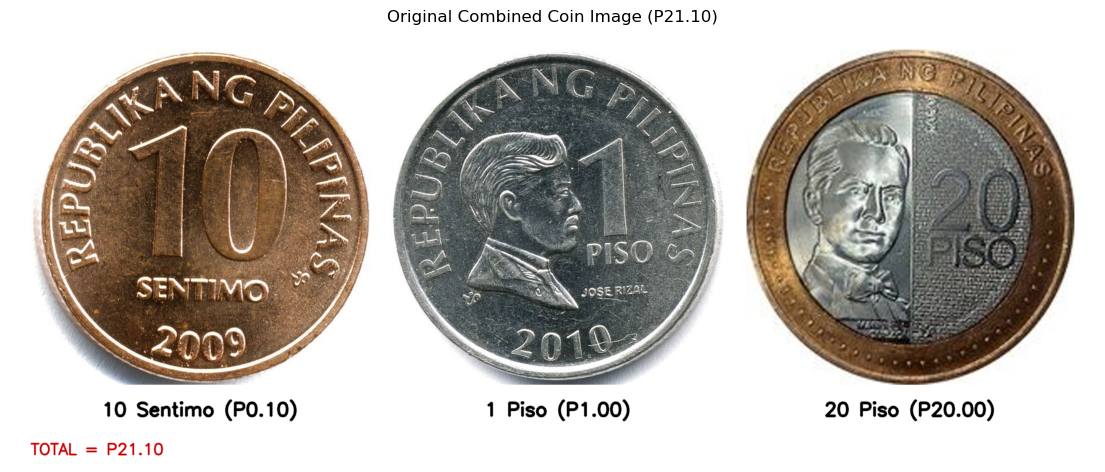

In [9]:
pad = 40
label_h = 110
total_w = sum(im.shape[1] for im in resized.values()) + pad * (len(resized) + 1)
canvas_h = TARGET_H + label_h + pad * 2
canvas = np.full((canvas_h, total_w, 3), 255, dtype=np.uint8)

x = pad
for name, im in resized.items():
    y = pad
    canvas[y:y + TARGET_H, x:x + im.shape[1]] = im
    text = f"{name} (P{values[name]:.2f})"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 1.2, 3)
    tx = x + (im.shape[1] - tw) // 2
    cv2.putText(canvas, text, (tx, y + TARGET_H + 60), cv2.FONT_HERSHEY_SIMPLEX,
                1.2, (0, 0, 0), 3, cv2.LINE_AA)
    x += im.shape[1] + pad

cv2.putText(canvas, f"TOTAL = P{total:.2f}", (pad, canvas_h - 15),
            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 200), 2, cv2.LINE_AA)

cv2.imwrite("01_original_combined.png", canvas)
show(canvas, "Original Combined Coin Image (P21.10)")

## 3. Pre-Processing

Raw coin photos are full of tiny surface texture, glare and shadows, and plain Canny edge
detection reacts to all of it — that is what makes outlines look broken and messy. Pre-processing
therefore does four things before any edge detector runs:

- **Grayscale conversion** — color is not needed for edges.
- **Illumination flattening** — the heavily blurred image (σ = 40) is subtracted so that glare and
  the left-right brightness change on the coins no longer hide the engravings (this is what brings
  out the faint *20* and *PISO* on the bi-metallic coin).
- **Median Filter (5×5)** — removes speckle noise while keeping edges sharp.
- **Bilateral + Gaussian Blur (σ = 1.5)** — smooth the metal grain but keep strong edges (numerals,
  portrait, lettering) intact.

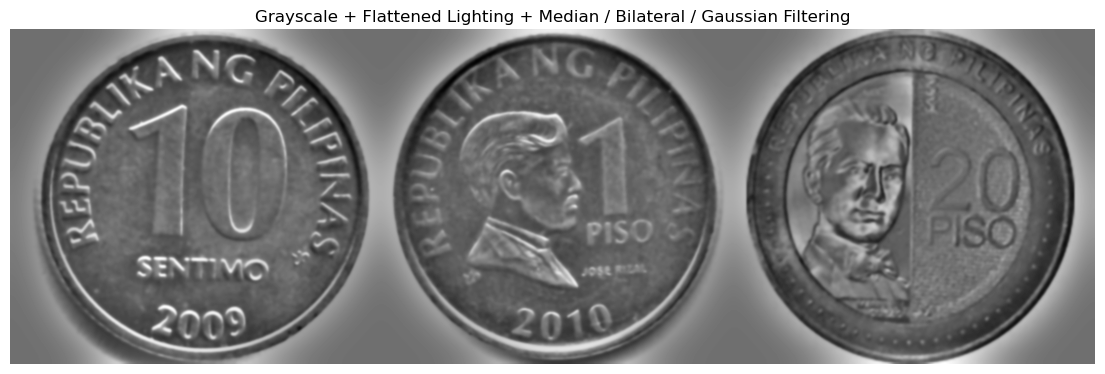

In [10]:
coin_row = canvas[pad:pad + TARGET_H, :].copy()
gray = cv2.cvtColor(coin_row, cv2.COLOR_BGR2GRAY)

background = cv2.GaussianBlur(gray.astype(np.float32), (0, 0), 40)
flat = cv2.normalize(gray.astype(np.float32) - background, None, 0, 255,
                     cv2.NORM_MINMAX).astype(np.uint8)

median_filtered   = cv2.medianBlur(flat, 5)
bilateral         = cv2.bilateralFilter(median_filtered, 9, 40, 7)
gaussian_filtered = cv2.GaussianBlur(bilateral, (0, 0), sigmaX=1.7)

cv2.imwrite("02_grayscale_filtered.png", gaussian_filtered)
show(gaussian_filtered, "Grayscale + Flattened Lighting + Median / Bilateral / Gaussian Filtering")

## 4. Apply Convolution — Sharpening Filter

A 3×3 sharpening kernel is convolved with the denoised image to re-emphasize the coin
engravings (numerals, portrait lines, lettering) that the blur step softened:

$$
K = \begin{bmatrix} 0 & -1 & 0 \\ -1 & 5 & -1 \\ 0 & -1 & 0 \end{bmatrix}
$$

The center pixel is weighted heavily (5) while its four direct neighbors are subtracted (−1 each).
This amplifies local intensity differences — i.e. edges and fine detail — while the kernel's
weights sum to 1, so flat, uniform regions stay roughly unchanged.

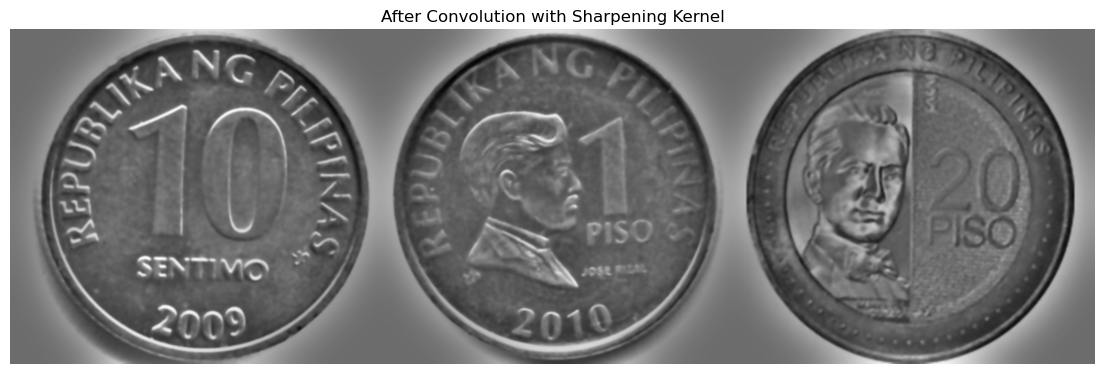

In [5]:
sharpen_kernel = np.array([
    [ 0, -1,  0],
    [-1,  5, -1],
    [ 0, -1,  0]
], dtype=np.float32)

sharpened = cv2.filter2D(gaussian_filtered, -1, sharpen_kernel)

cv2.imwrite("03_convolution_sharpened.png", sharpened)
show(sharpened, "After Convolution with Sharpening Kernel")

## 5. Perform Edge Detection

Two methods are applied to the sharpened image for comparison:

- **Sobel operator** — horizontal (Gx) and vertical (Gy) gradients combined into a gradient-magnitude
  ("edge strength") image.
- **Canny edge detector** — gradient + non-maximum suppression + double (hysteresis) thresholding.
  The thresholds are set from the image's *own gradient strength* (the high threshold is the 87th
  percentile of the Sobel magnitude inside the coins, the low threshold is 35 % of it), so only
  real engravings — not metal grain — survive.

Canny is used for the final result since its edges are thinner and better localized than Sobel's.

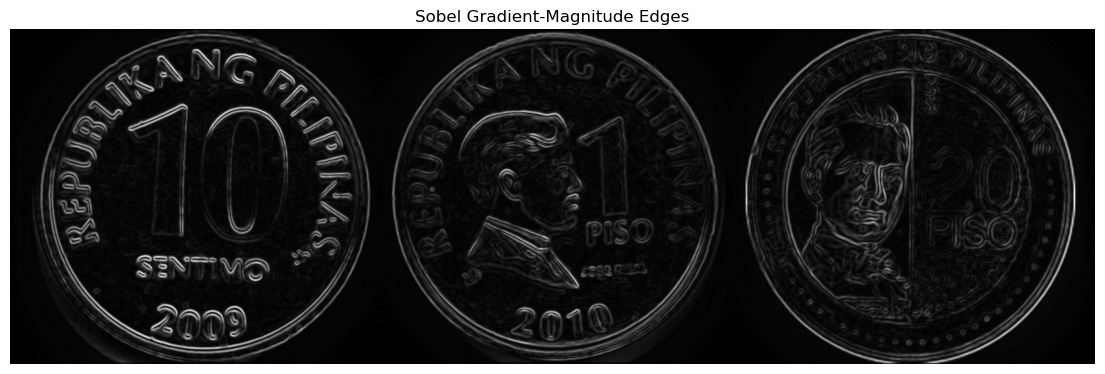

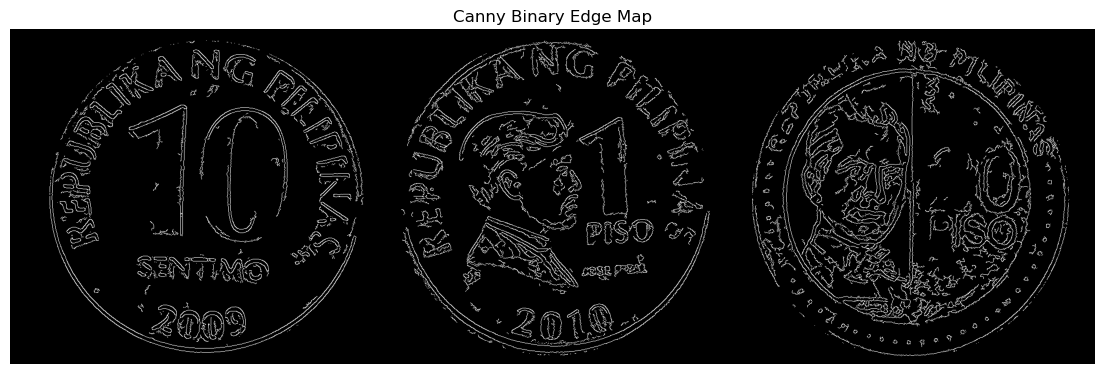

In [ ]:
circles = []
x_off = pad
for name, im in resized.items():
    g = cv2.GaussianBlur(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (9, 9), 2)
    found = cv2.HoughCircles(g, cv2.HOUGH_GRADIENT, dp=1.5, minDist=TARGET_H * 0.5,
                             param1=120, param2=60,
                             minRadius=int(TARGET_H * 0.38), maxRadius=int(TARGET_H * 0.52))
    if found is not None:
        cx, cy, r = found[0][0]
    else:                       
        cx, cy, r = im.shape[1] / 2, TARGET_H / 2, TARGET_H * 0.46
    circles.append((cx + x_off, cy, r))
    x_off += im.shape[1] + pad

coin_mask = np.zeros_like(gray)
for cx, cy, r in circles:
    cv2.circle(coin_mask, (int(cx), int(cy)), int(r * 0.97), 255, -1)

sobel_x = cv2.Sobel(sharpened, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(sharpened, cv2.CV_32F, 0, 1, ksize=3)
sobel_raw = cv2.magnitude(sobel_x, sobel_y)
sobel_mag = cv2.normalize(sobel_raw, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

high = np.percentile(sobel_raw[coin_mask > 0], 87)
low = 0.35 * high
canny_edges = cv2.Canny(sharpened, int(low), int(high))
canny_edges = cv2.bitwise_and(canny_edges, coin_mask)

cv2.imwrite("04a_sobel_edges.png", sobel_mag)
cv2.imwrite("04b_canny_edges.png", canny_edges)

show(sobel_mag, "Sobel Gradient-Magnitude Edges")
show(canny_edges, "Canny Binary Edge Map")

## 6. Clean the Result

The raw Canny output still has short stray fragments. Two clean-up steps fix this:

- **Connected-Component Filtering** — removes isolated edge fragments smaller than 130 pixels
  (almost always grain or glare, not a real engraving), leaving only long, continuous lines such as
  the **1**, **0**, **2**, the portraits and the lettering.
- **Morphological Closing (5×5)** — joins small gaps so numeral and letter strokes become continuous lines.
- **Gap linking** — every loose line end on the *10* and *20* is joined to the nearest neighboring line (within ~35 px), so the digits become continuous outlines. The *2* is faint, so it is traced separately: its dark stroke is found with a black-hat filter, thinned to a center line, and its pieces are joined.
- **Extra pass for the 20 Piso numerals** — the *20* is a gray digit on a gray panel, so that zone gets a local-contrast boost (CLAHE) and a black-hat outline before edge detection.
- **Coin boundary (circle) + dilation** — each coin's outer rim is drawn as one continuous
  ring, and the kept lines are thickened so they read clearly.

The cleaned edges are then overlaid in **green** on a faded grayscale copy of the coins, so the
numerals, portraits and lettering stay visible underneath the outlines.

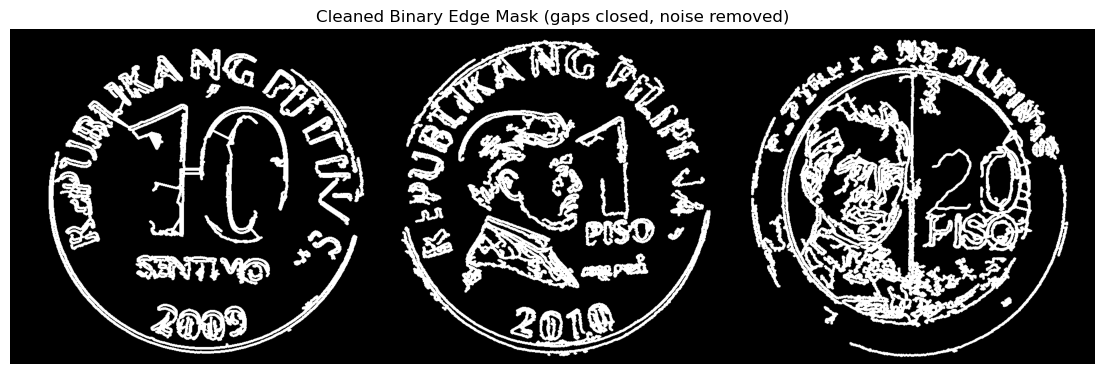

In [15]:
canny_closed = cv2.morphologyEx(canny_edges, cv2.MORPH_CLOSE,
                                cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

def keep_long(edge_img, min_area):
    n, lab, st, _ = cv2.connectedComponentsWithStats(edge_img, connectivity=8)
    out = np.zeros_like(edge_img)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= min_area:
            out[lab == i] = 255
    return out

def link_gaps(edge_img, max_dist=35):
    """Connect every free line end to the nearest *other* line within max_dist pixels."""
    e = (edge_img > 0).astype(np.uint8)
    _, lab = cv2.connectedComponents(e, connectivity=8)
    nbrs = cv2.filter2D(e, -1, np.ones((3, 3), np.float32), borderType=cv2.BORDER_CONSTANT)
    ends = np.argwhere((e == 1) & (nbrs <= 2))       
    pts = np.argwhere(e == 1)
    out = e.copy()
    for y, x in ends:
        d = np.hypot(pts[:, 0] - y, pts[:, 1] - x)
        near = (d <= max_dist) & (lab[pts[:, 0], pts[:, 1]] != lab[y, x])
        if near.any():
            j = np.argmin(np.where(near, d, 1e9))
            cv2.line(out, (int(x), int(y)), (int(pts[j, 1]), int(pts[j, 0])), 1, 1)
    return out * 255

cleaned = keep_long(canny_closed, 130)

# --- connect the broken lines of the 10 Sentimo numerals ---
cx, cy, r = circles[0]
a0, a1 = int(cx - 0.58 * r), int(cx + 0.58 * r)
b0, b1 = int(cy - 0.62 * r), int(cy + 0.34 * r)
zone10 = keep_long(canny_edges[b0:b1, a0:a1].copy(), 20)       
zone10 = link_gaps(zone10, 35)
zone10 = cv2.morphologyEx(zone10, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
zone10 = link_gaps(zone10, 45)
cleaned[b0:b1, a0:a1] = keep_long(zone10, 90)

# --- extra pass for the 20 Piso numerals (low contrast: gray digits on a gray panel) ---
cx, cy, r = circles[2]
x0, x1 = int(cx + 0.08 * r), int(cx + 0.74 * r)
y0, y1 = int(cy - 0.42 * r), int(cy + 0.36 * r)
cleaned[y0:y1, x0:x1] = 0                      
zone = bilateral[y0:y1, x0:x1]                  
zone = cv2.createCLAHE(clipLimit=3, tileGridSize=(4, 4)).apply(zone)   
smooth = cv2.GaussianBlur(zone, (0, 0), 1.5)
# dark strokes (blackhat) -> binary shape -> outline
blackhat = cv2.morphologyEx(smooth, cv2.MORPH_BLACKHAT,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (35, 35)))
_, shape = cv2.threshold(blackhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
shape = cv2.morphologyEx(shape, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
shape = keep_long(shape, 150)
outline = cv2.morphologyEx(shape, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8))
# Canny on the boosted zone adds the edges of the light-colored "2"
z = cv2.filter2D(cv2.GaussianBlur(zone, (0, 0), 2.2), -1, sharpen_kernel)
zm = cv2.magnitude(cv2.Sobel(z, cv2.CV_32F, 1, 0), cv2.Sobel(z, cv2.CV_32F, 0, 1))
zh = np.percentile(zm, 90)
ze = cv2.Canny(z, int(0.4 * zh), int(zh))
ze = keep_long(cv2.morphologyEx(ze, cv2.MORPH_CLOSE,
                                cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))), 120)
try:
    from skimage.morphology import skeletonize         
    outline_thin = (skeletonize(outline > 0) * 255).astype(np.uint8)
except ImportError:
    outline_thin = outline
zone20 = cv2.bitwise_or(outline_thin, ze)
zone20 = link_gaps(zone20, 35)                                  
zone20 = cv2.morphologyEx(zone20, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))

# --- trace the digit "2": its stroke is a thin dark ridge, so detect the ridge, thin it to a
#     1-px centre line, then join the pieces into one continuous line ---
zh_, zw_ = zone.shape
box2 = np.zeros_like(zone)
box2[int(0.096 * zh_):int(0.655 * zh_), int(0.03 * zw_):int(0.54 * zw_)] = 255
ridge = cv2.morphologyEx(smooth, cv2.MORPH_BLACKHAT,
                         cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (21, 21)))
ridge = cv2.bitwise_and(ridge, box2)
ridge_bin = (ridge > np.percentile(ridge[box2 > 0], 80)).astype(np.uint8) * 255
ridge_bin = cv2.morphologyEx(ridge_bin, cv2.MORPH_CLOSE,
                             cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
try:
    from skimage.morphology import skeletonize
    two = (skeletonize(ridge_bin > 0) * 255).astype(np.uint8)
except ImportError:
    two = cv2.erode(ridge_bin, np.ones((3, 3), np.uint8))
two = keep_long(two, 40)
two = link_gaps(two, 45)                      
two = link_gaps(two, 60)
zone20[box2 > 0] = 0                          
zone20 = cv2.bitwise_or(zone20, two)
cleaned[y0:y1, x0:x1] = zone20

# thicken so lines read clearly
cleaned = cv2.dilate(cleaned, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))

# faded grayscale background so the green lines stand out
faded = cv2.addWeighted(gray, 0.4, np.full_like(gray, 255), 0.6, 0)
final_bgr = cv2.cvtColor(faded, cv2.COLOR_GRAY2BGR)
final_bgr[cleaned == 255] = (0, 230, 0)
for cx, cy, r in circles:
    cv2.circle(final_bgr, (int(cx), int(cy)), int(r), (0, 230, 0), 5, cv2.LINE_AA)

show(cleaned, "Cleaned Binary Edge Mask (gaps closed, noise removed)")

## 7. Final Edge-Detected Output

The cleaned edges (green) are composited back onto the labeled canvas so the coins,
their denominations, and the ₱21.10 total can all be visually verified at once.

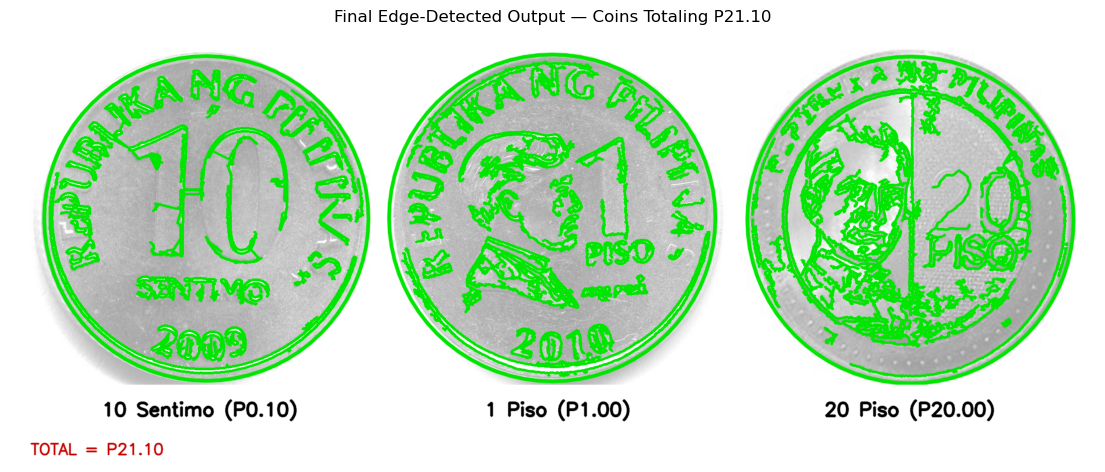

In [8]:
final_canvas = np.full((canvas_h, total_w, 3), 255, dtype=np.uint8)
final_canvas[pad:pad + TARGET_H, :] = final_bgr

x = pad
for name, im in resized.items():
    text = f"{name} (P{values[name]:.2f})"
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 1.2, 3)
    tx = x + (im.shape[1] - tw) // 2
    cv2.putText(final_canvas, text, (tx, pad + TARGET_H + 60), cv2.FONT_HERSHEY_SIMPLEX,
                1.2, (0, 0, 0), 3, cv2.LINE_AA)
    x += im.shape[1] + pad
cv2.putText(final_canvas, f"TOTAL = P{total:.2f}", (pad, canvas_h - 15),
            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 200), 2, cv2.LINE_AA)

cv2.imwrite("05_final_edge_detected.png", final_canvas)
show(final_canvas, "Final Edge-Detected Output — Coins Totaling P21.10")